# Instituto Superior de Engenharia do Porto (ISEP)
## Departamento de Engenharia Electrotécnica (DEE)
### Unidade Curricular: Sinais e Sistemas (SINSI), Licenciatura em Engenharia Electrotécnica e de Computadores

---
# Folha Prática TP07: Transformada de Fourier em Tempo Contínuo e Sistemas LIT
### Resolução Analítica Completa e Simulação Computacional em Python

Bem-vindos ao caderno prático da aula TP07. Neste documento aborda-se a **Transformada de Fourier em Tempo Contínuo (CTFT, *Continuous-Time Fourier Transform*)**, uma ferramenta basilar em engenharia para a representação espetral de sinais aperiódicos e para o projeto e caracterização de sistemas lineares e invariantes no tempo (LIT) no domínio da frequência.

O caderno organiza-se em três partes principais:
1. **Fundamentos Teóricos:** Transição intuitiva da Série para a Transformada de Fourier, propriedades operacionais (dualidade, convolução, diferenciação, escala), análise espetral de sistemas LIT e a sua relação estrutural com a Transformada de Laplace através de $s = j\omega$.
2. **Resolução Analítica Passo a Passo:** Dedução matemática completa dos exercícios propostos na folha prática TP07 (Exercícios 1.i, 1.k, 1.n, 3 e 15).
3. **Validação Computacional e Simulação:** Implementação de rotinas em Python com computação algébrica simbólica (`SymPy`), manipulação vetorial (`NumPy`), processamento de sinais (`SciPy`) e visualização gráfica (`Matplotlib`).

## 1. Enquadramento Teórico Formal

---

### 1.1. Da Série de Fourier à Transformada de Fourier

Nas aulas anteriores estudámos a **Série de Fourier em Tempo Contínuo (FS)**, aplicável exclusivamente a sinais periódicos $x(t) = x(t + T_0)$, com período fundamental $T_0$ e frequência angular fundamental $\omega_0 = \frac{2\pi}{T_0}$:
$$x(t) = \sum_{k=-\infty}^{+\infty} a_k e^{j k \omega_0 t}, \quad \text{onde } a_k = \frac{1}{T_0}\int_{-T_0/2}^{T_0/2} x(t) e^{-j k \omega_0 t} dt$$

Todavia, a grande maioria dos sinais com interesse prático em Engenharia Electrotécnica (impulsos transitórios, pulsos de relógio aperiódicos, respostas de comutação em circuitos RLC) não são periódicos. Para estender a representação harmónica a estes sinais, podemos interpretar um sinal aperiódico $x(t)$ como o caso limite de um sinal periódico quando o período fundamental tende para infinito ($T_0 \to \infty$).

A dedução desenvolve-se nos seguintes passos:

1. **Construção do sinal periódico auxiliar:**  
   Consideramos um sinal aperiódico $x(t)$ com duração finita ou decaimento assintótico rápido. Construímos um sinal periódico artificial $\tilde{x}(t)$, com período $T_0$, que coincide exatamente com $x(t)$ no intervalo central $[-T_0/2, T_0/2]$ e se repete indefinidamente no tempo.

2. **Cálculo dos coeficientes da Série de Fourier:**  
   Os coeficientes da série de $\tilde{x}(t)$ são dados por:
   $$a_k = \frac{1}{T_0} \int_{-T_0/2}^{T_0/2} \tilde{x}(t) e^{-j k \omega_0 t} dt = \frac{1}{T_0} \int_{-T_0/2}^{T_0/2} x(t) e^{-j k \omega_0 t} dt$$
   Fazendo o período $T_0$ suficientemente amplo para cobrir toda a zona significativa de $x(t)$, podemos alargar os limites de integração a todo o eixo temporal sem alterar o resultado:
   $$a_k = \frac{1}{T_0} \int_{-\infty}^{+\infty} x(t) e^{-j k \omega_0 t} dt$$

3. **Definição da função envelope contínua (Transformada de Fourier):**  
   Repare-se que a expressão entre parêntesis dentro da fórmula de $a_k$ não depende do período $T_0$, mas apenas da frequência discreta $k\omega_0$. Isto motiva a definição de uma função contínua da frequência angular $\omega$, designada por **Transformada de Fourier** $X(j\omega)$:
   $$X(j\omega) = \int_{-\infty}^{+\infty} x(t) e^{-j\omega t} dt$$
   Desta forma, os coeficientes discretos $a_k$ da série periódica correspondem a amostras pontuais dessa curva contínua $X(j\omega)$, tomadas a intervalos regulares de frequência $\omega_0$ e escaladas por $\frac{1}{T_0}$:
   $$a_k = \frac{1}{T_0} X(j k \omega_0)$$

4. **Reconstrução do sinal e passagem ao limite:**  
   Substituindo esta expressão de $a_k$ na síntese da Série de Fourier de $\tilde{x}(t)$:
   $$\tilde{x}(t) = \sum_{k=-\infty}^{+\infty} a_k e^{j k \omega_0 t} = \sum_{k=-\infty}^{+\infty} \frac{1}{T_0} X(j k \omega_0) e^{j k \omega_0 t}$$
   Como a frequência angular fundamental é $\omega_0 = \frac{2\pi}{T_0}$, o espaçamento entre riscas espetrais consecutivas é $\Delta\omega = \omega_0$, pelo que $\frac{1}{T_0} = \frac{\Delta\omega}{2\pi}$. Substituindo, obtemos:
   $$\tilde{x}(t) = \frac{1}{2\pi} \sum_{k=-\infty}^{+\infty} X(j k \omega_0) e^{j k \omega_0 t} \, \Delta\omega$$

5. **Interpretação da soma e passagem para o integral:**  
   Observe-se o significado geométrico desta soma: cada parcela $X(j k \omega_0) e^{j k \omega_0 t} \Delta\omega$ representa a área de um pequeno retângulo elementar de largura $\Delta\omega$ e altura $X(j k \omega_0) e^{j k \omega_0 t}$.  
   Quando fazemos o período tender para infinito ($T_0 \to \infty$):
   * O sinal periódico $\tilde{x}(t)$ passa a coincidir com o sinal aperiódico original $x(t)$ em toda a reta real: $\lim_{T_0 \to \infty} \tilde{x}(t) = x(t)$.
   * O espaçamento entre harmónicas $\Delta\omega = \frac{2\pi}{T_0}$ torna-se infinitesimal, passando a uma variação diferencial $d\omega$.
   * A variável discreta de frequência $k\omega_0$ torna-se uma variável contínua $\omega$.
   * A soma de áreas retangulares infinitesimais converge para a área total sob a curva, isto é, para um integral contínuo de $-\infty$ a $+\infty$:
   $$x(t) = \frac{1}{2\pi} \int_{-\infty}^{+\infty} X(j\omega) e^{j\omega t} d\omega$$

Estabelece-se deste modo o **Par de Transformadas de Fourier em Tempo Contínuo (CTFT)**:
$$\begin{cases}
\displaystyle X(j\omega) = \mathcal{F}\{x(t)\} = \int_{-\infty}^{+\infty} x(t) e^{-j\omega t} \, dt & \quad \text{(Equação de Análise)} \\
\displaystyle x(t) = \mathcal{F}^{-1}\{X(j\omega)\} = \frac{1}{2\pi} \int_{-\infty}^{+\infty} X(j\omega) e^{j\omega t} \, d\omega & \quad \text{(Equação de Síntese)}
\end{cases}$$

---

### 1.2. Condições de Convergência de Dirichlet

Para garantir que o integral de análise converge e a representação espetral existe sem ambiguidades, é suficiente que o sinal satisfaça as três **Condições de Dirichlet**:
1. **Absoluta integrabilidade:**
   $$\int_{-\infty}^{+\infty} |x(t)| \, dt < \infty$$
   Esta condição assegura que o integral não diverge, dado que $|X(j\omega)| \le \int_{-\infty}^{+\infty} |x(t) e^{-j\omega t}| dt = \int_{-\infty}^{+\infty} |x(t)| dt < \infty$.
2. **Número finito de extremos locais (máximos e mínimos)** em qualquer intervalo de tempo finito.
3. **Número finito de descontinuidades de amplitude finita** em qualquer intervalo de tempo finito.

> **Sinais com Impulsos no Domínio da Frequência:** Determinados sinais fundamentais que não cumprem estritamente a condição de absoluta integrabilidade (tais como o degrau de Heaviside $u(t)$, uma constante contínua ou uma sinusoide pura permanente) possuem ainda assim transformada de Fourier no sentido generalizado das distribuições, surgindo impulsos de Dirac $\delta(\omega)$ no espetro.

---

### 1.3. Interpretação Física e Propriedades de Simetria

A função complexa $X(j\omega)$ quantifica a **densidade espetral** do sinal $x(t)$, informando como a energia ou a amplitude do sinal se distribui pelas frequências contínuas $\omega$:
$$X(j\omega) = |X(j\omega)| e^{j \angle X(j\omega)} = \text{Re}\{X(j\omega)\} + j \, \text{Im}\{X(j\omega)\}$$

Para sinais reais ($x(t) \in \mathbb{R}$), verificam-se propriedades de simetria essenciais:
* **Simetria Conjugada (Hermitiana):** $X(-j\omega) = X^*(j\omega)$
* **Espetro de Magnitude:** é uma função par, $|X(-j\omega)| = |X(j\omega)|$
* **Espetro de Fase:** é uma função ímpar, $\angle X(-j\omega) = -\angle X(j\omega)$
* Se $x(t)$ for **real e par**, $X(j\omega)$ é **estritamente real e par** ($\text{Im}\{X(j\omega)\} = 0$).
* Se $x(t)$ for **real e ímpar**, $X(j\omega)$ é **puramente imaginário e ímpar** ($\text{Re}\{X(j\omega)\} = 0$).

---

### 1.4. Tabela de Propriedades Operacionais Fundamentais

| Propriedade | Domínio do Tempo $x(t)$ | Domínio da Frequência $X(j\omega)$ |
| :--- | :--- | :--- |
| **Linearidade** | $\alpha x_1(t) + \beta x_2(t)$ | $\alpha X_1(j\omega) + \beta X_2(j\omega)$ |
| **Deslocamento no Tempo** | $x(t - t_0)$ | $e^{-j\omega t_0} X(j\omega)$ |
| **Modulação (Deslocamento na Frequência)** | $e^{j\omega_0 t} x(t)$ | $X(j(\omega - \omega_0))$ |
| **Escalonamento Temporal** | $x(at), \quad a \neq 0$ | $\displaystyle \frac{1}{|a|} X\left(j\frac{\omega}{a}\right)$ |
| **Dualidade** | $X(jt)$ | $2\pi \, x(-\omega)$ |
| **Diferenciação no Tempo** | $\displaystyle \frac{d^n x(t)}{dt^n}$ | $(j\omega)^n X(j\omega)$ |
| **Diferenciação na Frequência** | $(-jt)^n x(t)$ | $\displaystyle \frac{d^n X(j\omega)}{d\omega^n}$ |
| **Integração no Tempo** | $\displaystyle \int_{-\infty}^{t} x(\tau) d\tau$ | $\displaystyle \frac{1}{j\omega} X(j\omega) + \pi X(0)\delta(\omega)$ |
| **Convolução no Tempo** | $x_1(t) * x_2(t)$ | $X_1(j\omega) X_2(j\omega)$ |
| **Multiplicação no Tempo** | $x_1(t) x_2(t)$ | $\displaystyle \frac{1}{2\pi} [X_1(j\omega) * X_2(j\omega)]$ |
| **Teorema de Parseval (Energia)** | $\displaystyle E = \int_{-\infty}^{+\infty} |x(t)|^2 dt$ | $\displaystyle \frac{1}{2\pi} \int_{-\infty}^{+\infty} |X(j\omega)|^2 d\omega$ |

---

### 1.5. Sistemas LIT e Resposta em Frequência

Para um sistema Linear e Invariante no Tempo (LIT) com resposta impulsional $h(t)$:
$$y(t) = x(t) * h(t) \stackrel{\mathcal{F}}{\longleftrightarrow} Y(j\omega) = H(j\omega) X(j\omega)$$
onde a **resposta em frequência** é a transformada de Fourier da resposta impulsional:
$$H(j\omega) = \mathcal{F}\{h(t)\} = \int_{-\infty}^{+\infty} h(t) e^{-j\omega t} dt$$

* **Sistemas em Série (Cascata):** Quando dois subsistemas $S_1$ e $S_2$ são associados em série, a convolução temporal converte-se no produto algébrico das respostas em frequência:
  $$H_{eq}(j\omega) = H_1(j\omega) \cdot H_2(j\omega)$$
* **Equações Diferenciais Lineares de Coeficientes Constantes (EDLCC):** Dada a equação de entrada e saída:
  $$\sum_{k=0}^N a_k \frac{d^k y(t)}{dt^k} = \sum_{m=0}^M b_m \frac{d^m x(t)}{dt^m}$$
  Aplicando a propriedade da diferenciação temporal ($\frac{d^k}{dt^k} \leftrightarrow (j\omega)^k$), obtém-se diretamente a função de transferência em frequência:
  $$H(j\omega) = \frac{Y(j\omega)}{X(j\omega)} = \frac{\sum_{m=0}^M b_m (j\omega)^m}{\sum_{k=0}^N a_k (j\omega)^k}$$

---

### 1.6. Relação com a Transformada de Laplace ($s = j\omega$)

A ligação entre a Transformada de Laplace bilateral e a Transformada de Fourier é um dos conceitos unificadores mais férteis da teoria de sinais:

1. **Definição e Conexão Matemática:**  
   A Transformada de Laplace de um sinal $x(t)$ é definida por:
   $$X(s) = \mathcal{L}\{x(t)\} = \int_{-\infty}^{+\infty} x(t) e^{-st} dt$$
   onde $s = \sigma + j\omega$ é a variável de frequência complexa. Substituindo $s = \sigma + j\omega$, temos:
   $$X(\sigma + j\omega) = \int_{-\infty}^{+\infty} \left[ x(t) e^{-\sigma t} \right] e^{-j\omega t} dt = \mathcal{F}\left\{ x(t) e^{-\sigma t} \right\}$$
   Ou seja, a Transformada de Laplace de $x(t)$ corresponde à Transformada de Fourier do sinal ponderado por uma exponencial real de amortecimento $e^{-\sigma t}$.

2. **Avaliação no Eixo Imaginário ($s = j\omega$):**  
   Quando fazemos $\sigma = 0$, a variável complexa situa-se exatamente sobre o eixo imaginário ($s = j\omega$). Se a **Região de Convergência (ROC)** de $X(s)$ contiver o eixo imaginário ($\sigma = 0$), a Transformada de Fourier obtém-se simplesmente avaliando $X(s)$ em $s = j\omega$:
   $$X(j\omega) = \left. X(s) \right|_{s = j\omega}$$

3. **Significado Físico em Engenharia Electrotécnica e Estabilidade:**  
   * Para a resposta impulsional de um circuito ou sistema LIT, a função de transferência de Laplace é $H(s)$, e a sua resposta em frequência é $H(j\omega) = \left. H(s) \right|_{s = j\omega}$.
   * Num sistema causal, a ROC de $H(s)$ situa-se à direita do polo de maior parte real: $\text{Re}\{s\} > \max(\text{Re}\{p_k\})$.
   * O sistema é **BIBO estável (*Bounded-Input, Bounded-Output*)** se e só se a resposta impulsional for absolutamente integrável ($\int |h(t)| dt < \infty$), o que equivale geometricamente a exigir que o **eixo imaginário pertença à ROC**, isto é, que **todos os polos do sistema tenham parte real estritamente negativa** ($\text{Re}\{p_k\} < 0$).
   * Fisicamente, se todos os polos estiverem no semiplano esquerdo, todos os regimes transitórios naturais do circuito decaem exponencialmente no tempo ($e^{\text{Re}\{p_k\}t} \to 0$), garantindo a existência de um regime permanente sinusoidal estável perante excitações de frequência angular $\omega$.

In [1]:
# ==============================================================================
# CONFIGURAÇÃO DO AMBIENTE DE CÁLCULO E ESTILO GRÁFICO
# ==============================================================================
import numpy as np
import scipy.signal as signal
import sympy as sp
import matplotlib.pyplot as plt

# Configuração de parâmetros gráficos para apresentação técnica e clara
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '--'

# Inicialização da impressão matemática no SymPy
sp.init_printing(use_unicode=True)

print("Ambiente computacional configurado com sucesso.")

Ambiente computacional configurado com sucesso.


## Exercício 1: Transformada de Fourier de Sinais Contínuos Elementares

Neste exercício determina-se analiticamente a transformada de Fourier $X(j\omega)$ de três sinais contínuos clássicos de suporte temporal ilimitado e limitado.

---

### Alínea 1.i) Sinal Exponencial Decrescente Bilateral
Considere o sinal contínuo:
$$x(t) = e^{-a|t|}, \quad a > 0$$

#### Resolução Analítica:
1. **Decomposição do sinal por intervalos:**  
   Pela definição de módulo, temos $|t| = t$ para $t \ge 0$ e $|t| = -t$ para $t < 0$. O sinal expressa-se pela soma de duas exponenciais unilaterais:
   $$x(t) = \begin{cases} e^{at}, & t < 0 \\ e^{-at}, & t \ge 0 \end{cases} \quad \Longleftrightarrow \quad x(t) = e^{at}u(-t) + e^{-at}u(t)$$
   Constata-se de imediato que $x(-t) = e^{-a|-t|} = e^{-a|t|} = x(t)$, pelo que $x(t)$ é um **sinal par e real**. Em consequência, o seu espetro de Fourier $X(j\omega)$ será necessariamente **estritamente real e par**.

2. **Cálculo do integral de Fourier:**  
   Aplicando a equação de análise:
   $$X(j\omega) = \int_{-\infty}^{+\infty} x(t) e^{-j\omega t} \, dt = \int_{-\infty}^{0} e^{at} e^{-j\omega t} \, dt + \int_{0}^{+\infty} e^{-at} e^{-j\omega t} \, dt$$

   Calculando a primeira parcela (integral para $t < 0$):
   $$\int_{-\infty}^{0} e^{(a - j\omega)t} \, dt = \left[ \frac{e^{(a - j\omega)t}}{a - j\omega} \right]_{-\infty}^{0}$$
   Como $a > 0$, quando $t \to -\infty$ temos $|e^{(a-j\omega)t}| = e^{at} \to 0$. Logo:
   $$\int_{-\infty}^{0} e^{(a - j\omega)t} \, dt = \frac{e^0}{a - j\omega} - 0 = \frac{1}{a - j\omega}$$

   Calculando a segunda parcela (integral para $t \ge 0$):
   $$\int_{0}^{+\infty} e^{-(a + j\omega)t} \, dt = \left[ \frac{e^{-(a + j\omega)t}}{-(a + j\omega)} \right]_{0}^{+\infty}$$
   Como $a > 0$, quando $t \to +\infty$ temos $|e^{-(a+j\omega)t}| = e^{-at} \to 0$. Logo:
   $$\int_{0}^{+\infty} e^{-(a + j\omega)t} \, dt = 0 - \left( -\frac{1}{a + j\omega} \right) = \frac{1}{a + j\omega}$$

3. **Combinação das parcelas:**  
   Somando as duas frações complexas conjugadas:
   $$X(j\omega) = \frac{1}{a - j\omega} + \frac{1}{a + j\omega} = \frac{(a + j\omega) + (a - j\omega)}{(a - j\omega)(a + j\omega)} = \frac{2a}{a^2 - j^2\omega^2} = \frac{2a}{a^2 + \omega^2}$$

#### Conclusão da Alínea 1.i:
$$\mathcal{F}\left\{ e^{-a|t|} \right\} = \frac{2a}{a^2 + \omega^2}, \quad a > 0$$

* **Propriedades Físicas Notáveis:**
  * O espetro é uma curva Lorentziana, estritamente real, sem desfasamento ($\angle X(j\omega) = 0$).
  * Em $\omega = 0$ (componente contínua ou DC), o valor coincide com a área total do sinal no tempo: $X(0) = \frac{2}{a} = \int_{-\infty}^{\infty} e^{-a|t|} dt$.
  * A frequência de corte a $-3\text{ dB}$ (frequência de meia potência) ocorre quando $a^2 + \omega^2 = 2a^2 \implies \omega_c = a\text{ rad/s}$.
  * Princípio da reciprocidade tempo-frequência: à medida que $a$ aumenta, o sinal decai mais rapidamente no tempo (torna-se mais estreito) e o seu espetro na frequência alarga-se ($\omega_c$ aumenta), reduzindo o valor de pico.

=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 1.i ===
Integral em (-inf, 0): Piecewise((1/(a*(1 - I*w/a)), Abs(arg(w) - pi/2) <= pi/2), (Integral(exp(a*t)*exp(-I*t*w), (t, -oo, 0)), True))
Integral em (0, +inf): Piecewise((1/(a*(1 + I*w/a)), Abs(arg(w) + pi/2) <= pi/2), (Integral(exp(-a*t)*exp(-I*t*w), (t, 0, oo)), True))
X(jw) = I_neg + I_pos: Piecewise((2*a/(a**2 + w**2), (Abs(2*arg(w) + pi) <= pi) & ((Abs(2*arg(w) - pi) <= pi) | (Abs(arg(a - I*w)) < pi/2))), (((a + I*w)*Integral(exp(t*(a - I*w)), (t, -oo, 0)) + 1)/(a + I*w), Abs(2*arg(w) + pi) <= pi), (2*a/(a**2 + w**2), (Abs(2*arg(w) - pi) <= pi) & (Abs(arg(a + I*w)) < pi/2)), (((a - I*w)*Integral(exp(-t*(a + I*w)), (t, 0, oo)) + 1)/(a - I*w), Abs(2*arg(w) - pi) <= pi), (2*a/(a**2 + w**2), (Abs(arg(a + I*w)) < pi/2) & (Abs(arg(a - I*w)) < pi/2)), (((a + I*w)*Integral(exp(t*(a - I*w)), (t, -oo, 0)) + 1)/(a + I*w), Abs(arg(a + I*w)) < pi/2), (((a - I*w)*Integral(exp(-t*(a + I*w)), (t, 0, oo)) + 1)/(a - I*w), Abs(arg(a - I*w)) < pi/2)

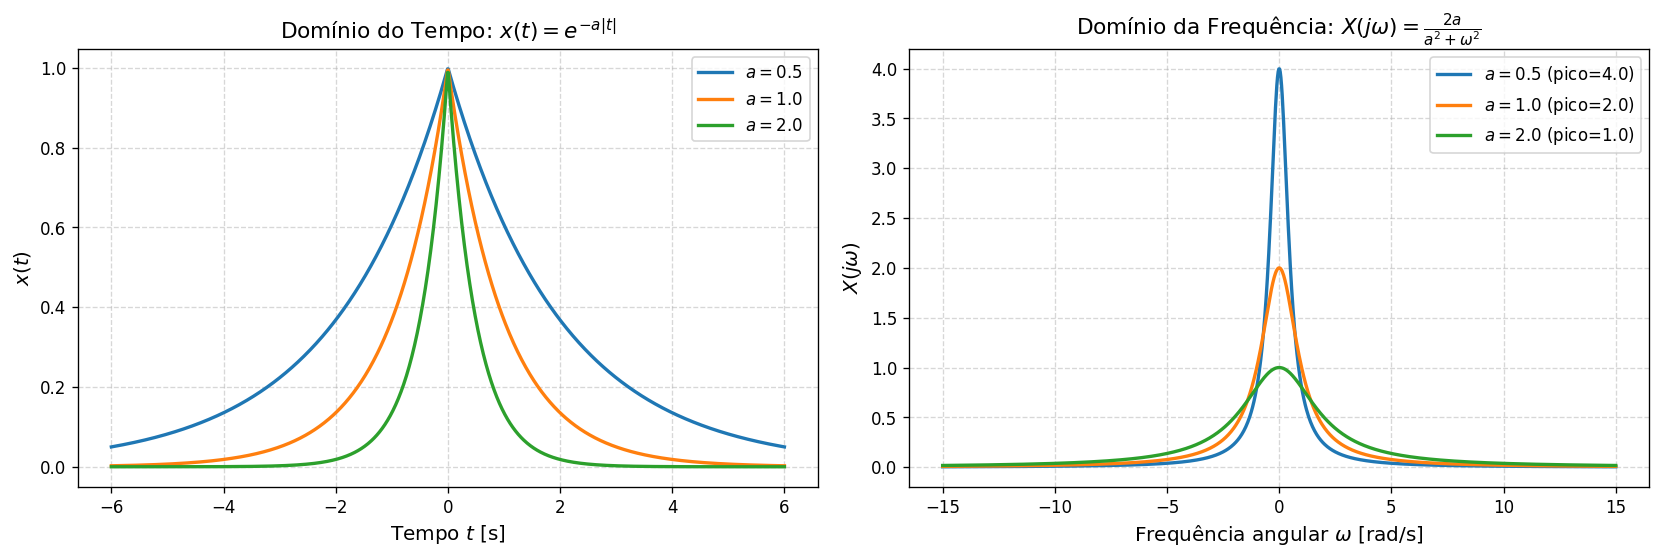

In [2]:
# ==============================================================================
# EXERCÍCIO 1.i: Verificação Simbólica e Análise Paramétrica
# ==============================================================================

# 1. Dedução Simbólica com SymPy
t, w = sp.symbols('t w', real=True)
a = sp.symbols('a', positive=True)

# Definição do sinal por ramos para integração analítica
x1_neg = sp.exp(a*t)
x1_pos = sp.exp(-a*t)

I_neg = sp.integrate(x1_neg * sp.exp(-sp.I*w*t), (t, -sp.oo, 0))
I_pos = sp.integrate(x1_pos * sp.exp(-sp.I*w*t), (t, 0, sp.oo))
X1_sym = sp.simplify(I_neg + I_pos)

print("=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 1.i ===")
print("Integral em (-inf, 0):", I_neg)
print("Integral em (0, +inf):", I_pos)
print("X(jw) = I_neg + I_pos:", X1_sym)
print("Expressão Teórica:    ", 2*a / (a**2 + w**2))

# 2. Visualização Numérica: Efeito do parâmetro 'a' no Tempo e na Frequência
t_vals = np.linspace(-6, 6, 1000)
w_vals = np.linspace(-15, 15, 1000)
a_list = [0.5, 1.0, 2.0]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

fig, (ax_t, ax_w) = plt.subplots(1, 2, figsize=(14, 4.8))

for a_val, col in zip(a_list, colors):
    # Sinal no tempo
    x_vals = np.exp(-a_val * np.abs(t_vals))
    ax_t.plot(t_vals, x_vals, label=rf'$a = {a_val}$', color=col)
    
    # Espetro na frequência
    X_vals = (2 * a_val) / (a_val**2 + w_vals**2)
    ax_w.plot(w_vals, X_vals, label=rf'$a = {a_val}$ (pico={2/a_val:.1f})', color=col)

ax_t.set_title(r'Domínio do Tempo: $x(t) = e^{-a|t|}$')
ax_t.set_xlabel('Tempo $t$ [s]')
ax_t.set_ylabel('$x(t)$')
ax_t.grid(True)
ax_t.legend()

ax_w.set_title(r'Domínio da Frequência: $X(j\omega) = \frac{2a}{a^2 + \omega^2}$')
ax_w.set_xlabel(r'Frequência angular $\omega$ [rad/s]')
ax_w.set_ylabel(r'$X(j\omega)$')
ax_w.grid(True)
ax_w.legend()

plt.tight_layout()
plt.show()

### Alínea 1.k) Sinal de Cauchy / Racional
Considere o sinal contínuo:
$$x(t) = \frac{1}{a^2 + t^2}, \quad a > 0$$

#### Resolução Analítica:
1. **Identificação da Estrutura Funcional e da Propriedade da Dualidade:**  
   O cálculo direto de $X(j\omega) = \int_{-\infty}^{\infty} \frac{e^{-j\omega t}}{a^2 + t^2} dt$ envolveria integração no plano complexo através do Teorema dos Resíduos de Cauchy. Contudo, em Sinais e Sistemas, a abordagem mais imediata e conceptual decorre da aplicação da **Propriedade da Dualidade**.

   A propriedade da dualidade estabelece que:
   $$\text{Se } g(t) \stackrel{\mathcal{F}}{\longleftrightarrow} G(j\omega), \quad \text{então } G(jt) \stackrel{\mathcal{F}}{\longleftrightarrow} 2\pi \, g(-\omega)$$
   onde $G(jt)$ representa a função analítica $G(j\omega)$ na qual a variável formal de frequência $\omega$ é substituída pela variável contínua de tempo $t$.

2. **Aplicação do Par Obtido na Alínea 1.i:**  
   Do exercício anterior, conhecemos o par de transformada:
   $$g(t) = e^{-a|t|} \stackrel{\mathcal{F}}{\longleftrightarrow} G(j\omega) = \frac{2a}{a^2 + \omega^2}$$

   Substituindo formalmente $\omega \to t$:
   $$G(jt) = \frac{2a}{a^2 + t^2}$$

   Pela propriedade da dualidade, a transformada de Fourier de $G(jt)$ é dada por:
   $$\mathcal{F}\left\{ G(jt) \right\} = 2\pi \, g(-\omega) = 2\pi e^{-a|-\omega|} = 2\pi e^{-a|\omega|}$$

3. **Aplicação da Propriedade da Linearidade:**  
   Sendo a transformada de Fourier uma operação linear, dividimos ambos os membros pela constante escalar $2a$:
   $$\mathcal{F}\left\{ \frac{1}{2a} G(jt) \right\} = \frac{1}{2a} \cdot 2\pi e^{-a|\omega|}$$
   $$\mathcal{F}\left\{ \frac{1}{a^2 + t^2} \right\} = \frac{\pi}{a} e^{-a|\omega|}$$

#### Conclusão da Alínea 1.k:
$$\mathcal{F}\left\{ \frac{1}{a^2 + t^2} \right\} = \frac{\pi}{a} e^{-a|\omega|}, \quad a > 0$$

* **Comentário Didático:**  
  Note-se a simetria espelhada entre os pares 1.i e 1.k:
  $$e^{-a|t|} \stackrel{\mathcal{F}}{\longleftrightarrow} \frac{2a}{a^2 + \omega^2} \quad \Longleftrightarrow \quad \frac{1}{a^2 + t^2} \stackrel{\mathcal{F}}{\longleftrightarrow} \frac{\pi}{a} e^{-a|\omega|}$$
  No tempo tínhamos uma função de decaimento algébrico suave $\mathcal{O}(t^{-2})$ com um topo arredondado; na frequência obtemos um decaimento exponencial bilateral rápido $\mathcal{O}(e^{-a|\omega|})$, com uma cúspide (descontinuidade na derivada primeira) em $\omega = 0$.

=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 1.k ===
Integral de x(t)*cos(w*t) dt:  Piecewise((pi*exp(-a*w)/a, Eq(Abs(arg(w)), 0)), (Integral(cos(t*w)/(a**2 + t**2), (t, -oo, oo)), True))
Expressão obtida por Dualidade: (pi/a)*exp(-a*|w|)


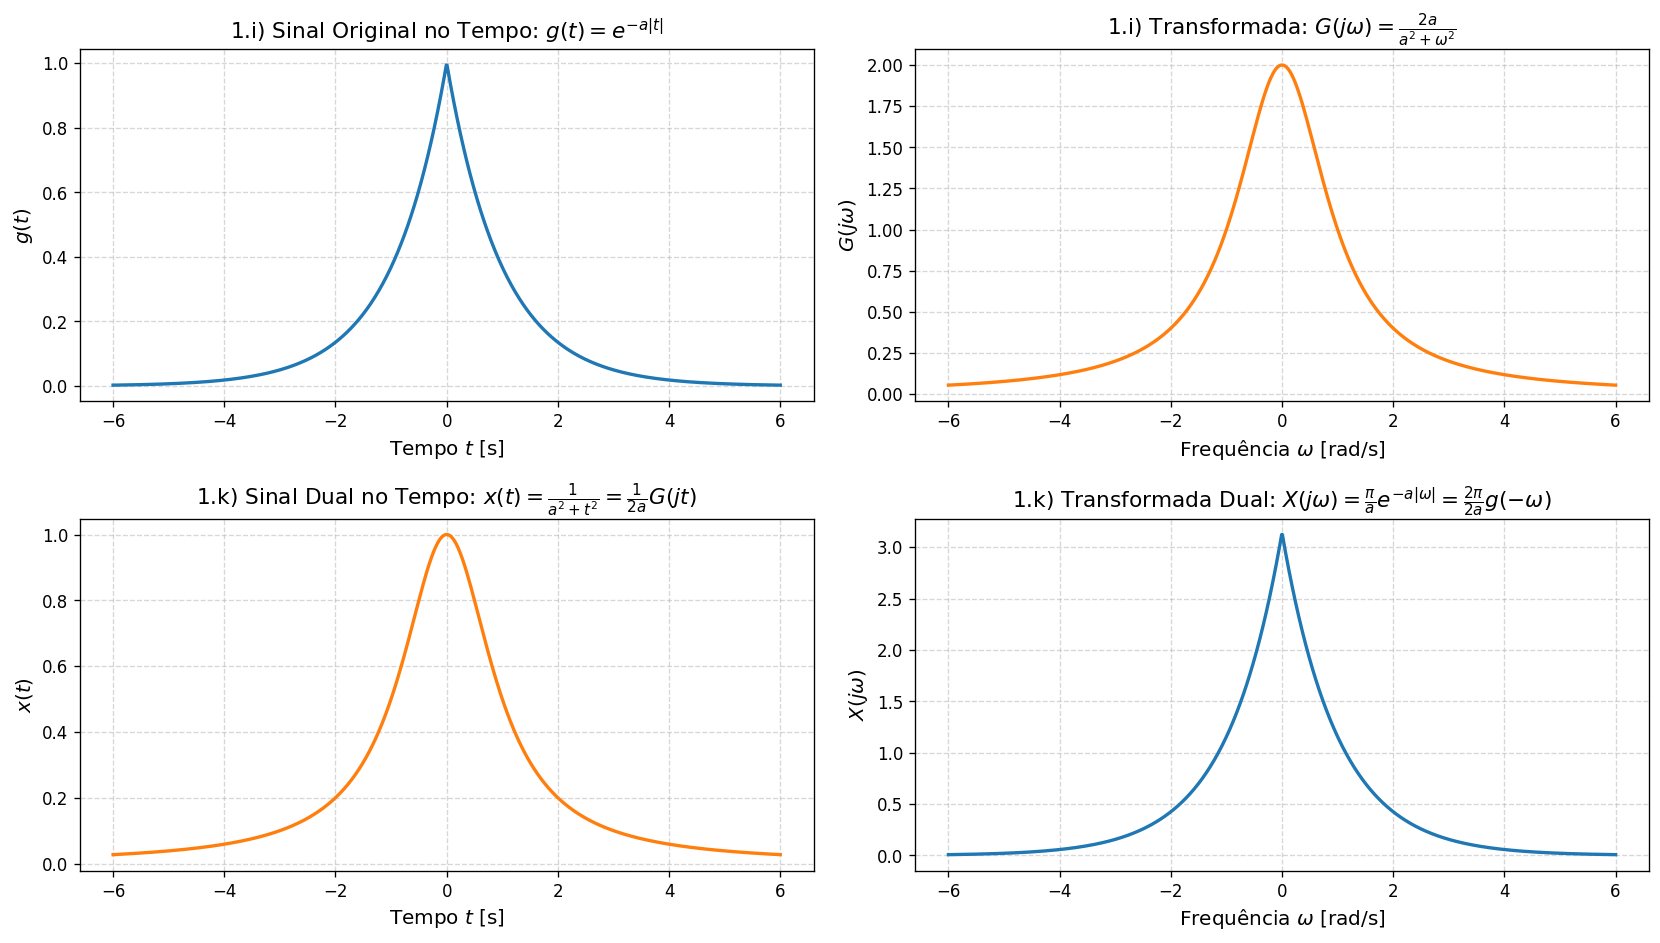

In [3]:
# ==============================================================================
# EXERCÍCIO 1.k: Demonstração da Dualidade e Visualização Gráfica
# ==============================================================================

# 1. Demonstração Simbólica Integral com SymPy
t, w = sp.symbols('t w', real=True)
a = sp.symbols('a', positive=True)

x_k = 1 / (a**2 + t**2)

# Cálculo do integral de Fourier através da paridade: integral x(t)*cos(w*t) dt
X_k_direct = sp.integrate(x_k * sp.cos(w*t), (t, -sp.oo, sp.oo))

print("=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 1.k ===")
print("Integral de x(t)*cos(w*t) dt: ", sp.simplify(X_k_direct))
print("Expressão obtida por Dualidade: (pi/a)*exp(-a*|w|)")

# 2. Comparação Visual dos Pares Duais (1.i vs 1.k)
a_fixo = 1.0
t_axis = np.linspace(-6, 6, 1000)
w_axis = np.linspace(-6, 6, 1000)

fig, axs = plt.subplots(2, 2, figsize=(14, 8))

# Linha 1: Par Original (1.i)
axs[0, 0].plot(t_axis, np.exp(-a_fixo * np.abs(t_axis)), color='#1f77b4')
axs[0, 0].set_title(r'1.i) Sinal Original no Tempo: $g(t) = e^{-a|t|}$')
axs[0, 0].set_xlabel('Tempo $t$ [s]')
axs[0, 0].set_ylabel('$g(t)$')
axs[0, 0].grid(True)

axs[0, 1].plot(w_axis, 2 * a_fixo / (a_fixo**2 + w_axis**2), color='#ff7f0e')
axs[0, 1].set_title(r'1.i) Transformada: $G(j\omega) = \frac{2a}{a^2 + \omega^2}$')
axs[0, 1].set_xlabel(r'Frequência $\omega$ [rad/s]')
axs[0, 1].set_ylabel(r'$G(j\omega)$')
axs[0, 1].grid(True)

# Linha 2: Par Dual (1.k)
axs[1, 0].plot(t_axis, 1 / (a_fixo**2 + t_axis**2), color='#ff7f0e')
axs[1, 0].set_title(r'1.k) Sinal Dual no Tempo: $x(t) = \frac{1}{a^2 + t^2} = \frac{1}{2a} G(jt)$')
axs[1, 0].set_xlabel('Tempo $t$ [s]')
axs[1, 0].set_ylabel('$x(t)$')
axs[1, 0].grid(True)

axs[1, 1].plot(w_axis, (np.pi / a_fixo) * np.exp(-a_fixo * np.abs(w_axis)), color='#1f77b4')
axs[1, 1].set_title(r'1.k) Transformada Dual: $X(j\omega) = \frac{\pi}{a} e^{-a|\omega|} = \frac{2\pi}{2a} g(-\omega)$')
axs[1, 1].set_xlabel(r'Frequência $\omega$ [rad/s]')
axs[1, 1].set_ylabel(r'$X(j\omega)$')
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

### Alínea 1.n) Pulso Retangular
Considere o sinal contínuo:
$$x(t) = \Pi\left( \frac{t}{2a} \right), \quad a > 0$$

#### Resolução Analítica:
1. **Definição da função porta/pulso retangular:**  
   Pela definição da função pulso retangular unitário $\Pi\left(\frac{t}{T_p}\right)$, temos um sinal com amplitude unitária centrado na origem e de largura total $T_p = 2a$:
   $$x(t) = \begin{cases} 1, & -\frac{T_p}{2} \le t \le \frac{T_p}{2} \\ 0, & |t| > \frac{T_p}{2} \end{cases} \quad \Longleftrightarrow \quad x(t) = \begin{cases} 1, & -a \le t \le a \\ 0, & |t| > a \end{cases}$$
   O sinal é real e par, com suporte temporal compacto $[-a, a]$.

2. **Cálculo do integral de Fourier:**  
   $$X(j\omega) = \int_{-\infty}^{+\infty} x(t) e^{-j\omega t} \, dt = \int_{-a}^{a} 1 \cdot e^{-j\omega t} \, dt$$

   Para $\omega \neq 0$:
   $$X(j\omega) = \left[ \frac{e^{-j\omega t}}{-j\omega} \right]_{-a}^{a} = \frac{e^{-j\omega a} - e^{j\omega a}}{-j\omega} = \frac{e^{j\omega a} - e^{-j\omega a}}{j\omega}$$

   Recordando a relação de Euler para o seno, $\sin(\theta) = \frac{e^{j\theta} - e^{-j\theta}}{2j} \implies e^{j\theta} - e^{-j\theta} = 2j\sin(\theta)$:
   $$X(j\omega) = \frac{2j\sin(\omega a)}{j\omega} = \frac{2\sin(\omega a)}{\omega}$$

   Multiplicando e dividindo o denominador pelo fator de escala $a$:
   $$X(j\omega) = 2a \, \frac{\sin(\omega a)}{\omega a}$$

3. **Notação através da função $\text{sinc}$:**  
   Na literatura técnica usam-se habitualmente duas convenções:
   * **Função $\text{sinc}$ normalizada:** $\text{sinc}(u) = \frac{\sin(\pi u)}{\pi u}$. Nesta notação:
     $$X(j\omega) = 2a \, \text{sinc}\left( \frac{\omega a}{\pi} \right)$$
   * **Função de amostragem (Sampling ou Sa):** $\text{Sa}(\theta) = \frac{\sin(\theta)}{\theta}$. Nesta notação:
     $$X(j\omega) = 2a \, \text{Sa}(\omega a)$$

   Para o caso particular $\omega = 0$:
   $$X(j0) = \lim_{\omega \to 0} 2a \frac{\sin(\omega a)}{\omega a} = 2a \times 1 = 2a = \text{Área sob o pulso}$$

#### Conclusão da Alínea 1.n:
$$\mathcal{F}\left\{ \Pi\left( \frac{t}{2a} \right) \right\} = 2a \, \frac{\sin(\omega a)}{\omega a} = 2a \, \text{sinc}\left( \frac{\omega a}{\pi} \right), \quad a > 0$$

* **Propriedades Espetrais:**
  * **Zeros do espetro:** $\sin(\omega a) = 0 \implies \omega a = k\pi \implies \omega_k = \frac{k\pi}{a}, \quad k \in \mathbb{Z} \setminus \{0\}$.
  * **Lobo principal:** compreendido entre os primeiros cruzamentos por zero, $-\frac{\pi}{a} < \omega < \frac{\pi}{a}$, com largura total de $\Delta\omega_{lp} = \frac{2\pi}{a}\text{ rad/s}$.
  * **Fase:** como $X(j\omega)$ alterna entre valores positivos e negativos nos lobos, a magnitude é $|X(j\omega)| = 2a \left| \frac{\sin(\omega a)}{\omega a} \right|$ e a fase $\angle X(j\omega)$ vale $0$ radianos nos lobos onde $X(j\omega) > 0$, e $\pm \pi$ radianos onde $X(j\omega) < 0$.

=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 1.n ===
Integral de exp(-j*w*t) entre -a e a: Piecewise((2*sin(a*w)/w, (w > 0) | (w < 0)), (2*a, True))
Expressão Equivalente 2*a*sinc(w*a): 2*sin(a*w)/w


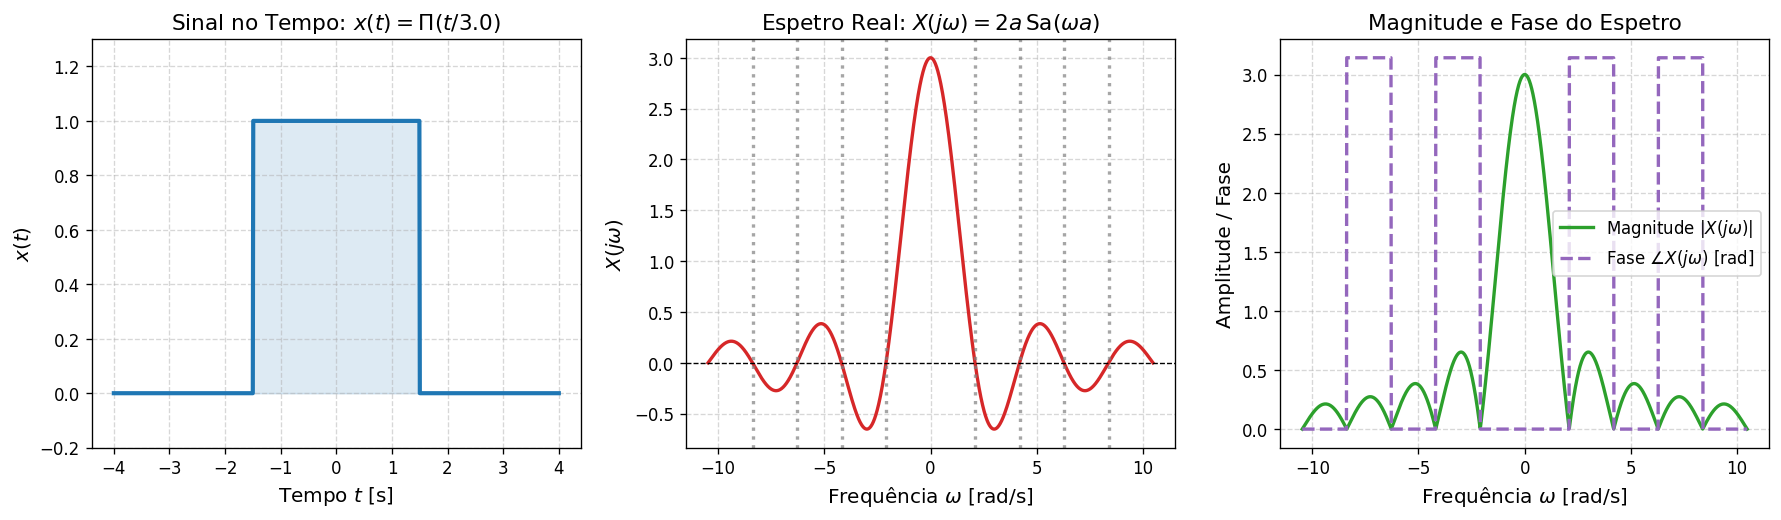

In [4]:
# ==============================================================================
# EXERCÍCIO 1.n: Simulação do Pulso Retangular e Respetivo Espetro Sinc
# ==============================================================================

t, w = sp.symbols('t w', real=True)
a = sp.symbols('a', positive=True)

# 1. Integração Simbólica com SymPy
X_rect_sym = sp.integrate(1 * sp.exp(-sp.I*w*t), (t, -a, a))
X_rect_simp = sp.simplify(X_rect_sym.rewrite(sp.sin))

print("=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 1.n ===")
print("Integral de exp(-j*w*t) entre -a e a:", X_rect_simp)
print("Expressão Equivalente 2*a*sinc(w*a):", 2*sp.sin(w*a)/w)

# 2. Visualização Gráfica do Pulso e Análise de Magnitude e Fase
a_val = 1.5
t_grid = np.linspace(-4, 4, 1000)
x_rect = np.where(np.abs(t_grid) <= a_val, 1.0, 0.0)

w_grid = np.linspace(-5 * np.pi / a_val, 5 * np.pi / a_val, 1500)
# Expressão contínua com tratamento da divisão por zero em w=0
X_rect_vals = np.where(w_grid == 0, 2 * a_val, 2 * np.sin(w_grid * a_val) / w_grid)

mag_X = np.abs(X_rect_vals)
phase_X = np.angle(X_rect_vals)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))

# Sinal no tempo
axs[0].plot(t_grid, x_rect, color='#1f77b4', linewidth=2.5)
axs[0].fill_between(t_grid, x_rect, color='#1f77b4', alpha=0.15)
axs[0].set_title(rf'Sinal no Tempo: $x(t) = \Pi(t / {2*a_val})$')
axs[0].set_xlabel('Tempo $t$ [s]')
axs[0].set_ylabel('$x(t)$')
axs[0].set_ylim(-0.2, 1.3)
axs[0].grid(True)

# Espetro Real / Amplitude
axs[1].plot(w_grid, X_rect_vals, color='#d62728', label=r'$X(j\omega)$')
axs[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
for k in range(-4, 5):
    if k != 0:
        axs[1].axvline(k * np.pi / a_val, color='gray', linestyle=':', alpha=0.7)
axs[1].set_title(r'Espetro Real: $X(j\omega) = 2a\, \mathrm{Sa}(\omega a)$')
axs[1].set_xlabel(r'Frequência $\omega$ [rad/s]')
axs[1].set_ylabel(r'$X(j\omega)$')
axs[1].grid(True)

# Espetro de Magnitude e Fase
axs[2].plot(w_grid, mag_X, color='#2ca02c', label=r'Magnitude $|X(j\omega)|$')
axs[2].plot(w_grid, phase_X, color='#9467bd', linestyle='--', label=r'Fase $\angle X(j\omega)$ [rad]')
axs[2].set_title('Magnitude e Fase do Espetro')
axs[2].set_xlabel(r'Frequência $\omega$ [rad/s]')
axs[2].set_ylabel('Amplitude / Fase')
axs[2].grid(True)
axs[2].legend()

plt.tight_layout()
plt.show()

## Exercício 3: Propriedade da Convolução no Tempo e Inversão da Transformada

Considere o enunciado do exercício:
> Determine a transformada de Fourier, $X(j\omega)$, do sinal $x(t) = e^{-at}u(t)$, $a > 0$ e, com base nesse resultado, obtenha a transformada inversa de Fourier de $Y(j\omega) = \frac{1}{(a + j\omega)^2}$ usando a propriedade da convolução no tempo.

---

### Resolução Analítica:

#### Parte 1: Determinação da Transformada de Fourier $X(j\omega)$
O sinal é causal, correspondendo a um decaimento exponencial com início em $t = 0$:
$$x(t) = e^{-at}u(t) = \begin{cases} e^{-at}, & t \ge 0 \\ 0, & t < 0 \end{cases}, \quad a > 0$$

Aplicando o integral de definição:
$$X(j\omega) = \int_{-\infty}^{+\infty} x(t) e^{-j\omega t} \, dt = \int_{0}^{+\infty} e^{-at} e^{-j\omega t} \, dt = \int_{0}^{+\infty} e^{-(a + j\omega)t} \, dt$$

Calculando a primitiva:
$$X(j\omega) = \left[ \frac{e^{-(a + j\omega)t}}{-(a + j\omega)} \right]_{0}^{+\infty}$$

Dado que $a > 0$:
$$\lim_{t \to +\infty} |e^{-(a + j\omega)t}| = \lim_{t \to +\infty} e^{-at} \cdot |e^{-j\omega t}| = \lim_{t \to +\infty} e^{-at} \cdot 1 = 0$$

Logo:
$$X(j\omega) = 0 - \left( -\frac{1}{a + j\omega} \right) = \frac{1}{a + j\omega}$$

#### Parte 2: Relação entre $Y(j\omega)$ e $X(j\omega)$
Analisando a estrutura algébrica de $Y(j\omega)$:
$$Y(j\omega) = \frac{1}{(a + j\omega)^2} = \left( \frac{1}{a + j\omega} \right) \cdot \left( \frac{1}{a + j\omega} \right) = X(j\omega) \cdot X(j\omega)$$

#### Parte 3: Aplicação da Propriedade da Convolução no Tempo
A propriedade da convolução no tempo estabelece que a multiplicação no domínio da frequência é dual da convolução contínua no domínio do tempo:
$$x_1(t) * x_2(t) \stackrel{\mathcal{F}}{\longleftrightarrow} X_1(j\omega) \cdot X_2(j\omega)$$

Fazendo $x_1(t) = x_2(t) = x(t) = e^{-at}u(t)$:
$$y(t) = \mathcal{F}^{-1}\{Y(j\omega)\} = \mathcal{F}^{-1}\{X(j\omega) \cdot X(j\omega)\} = x(t) * x(t)$$

#### Parte 4: Cálculo do Integral de Convolução $y(t) = x(t) * x(t)$
Pela definição do integral de convolução contínua:
$$y(t) = \int_{-\infty}^{+\infty} x(\tau) \, x(t - \tau) \, d\tau$$

Substituindo as expressões temporais:
$$x(\tau) = e^{-a\tau} u(\tau), \quad x(t - \tau) = e^{-a(t - \tau)} u(t - \tau)$$
$$y(t) = \int_{-\infty}^{+\infty} e^{-a\tau} u(\tau) \cdot e^{-a(t - \tau)} u(t - \tau) \, d\tau$$

Análise do produto dos dois degraus de Heaviside $u(\tau) \cdot u(t - \tau)$:
* $u(\tau) = 1 \iff \tau \ge 0$
* $u(t - \tau) = 1 \iff t - \tau \ge 0 \iff \tau \le t$

1. **Caso 1: $t < 0$**  
   Os intervalos $\tau \ge 0$ e $\tau \le t$ não se sobrepõem. O integrando é identicamente nulo:
   $$y(t) = 0, \quad \forall t < 0$$

2. **Caso 2: $t \ge 0$**  
   O integrando é não nulo no intervalo finito $\tau \in [0, t]$:
   $$y(t) = \int_{0}^{t} e^{-a\tau} e^{-a(t - \tau)} \, d\tau = \int_{0}^{t} e^{-a\tau} e^{-at} e^{a\tau} \, d\tau$$
   Como $e^{-a\tau} e^{a\tau} = e^0 = 1$ e o termo $e^{-at}$ é constante face à variável de integração $\tau$:
   $$y(t) = e^{-at} \int_{0}^{t} 1 \, d\tau = e^{-at} \cdot [\tau]_{0}^{t} = e^{-at} \cdot (t - 0) = t \, e^{-at}$$

Reunindo os dois intervalos através da função degrau de Heaviside $u(t)$:
$$y(t) = t e^{-at} u(t)$$

---

#### Validação Alternativa Pedagógica (Diferenciação na Frequência):
Podemos confirmar a exatidão deste resultado recorrendo à propriedade da diferenciação na frequência:
$$(-jt) x(t) \stackrel{\mathcal{F}}{\longleftrightarrow} \frac{d X(j\omega)}{d\omega} \quad \Longleftrightarrow \quad t x(t) \stackrel{\mathcal{F}}{\longleftrightarrow} j \frac{d X(j\omega)}{d\omega}$$

Dado $x(t) = e^{-at}u(t)$ e $X(j\omega) = (a + j\omega)^{-1}$:
$$\frac{d X(j\omega)}{d\omega} = \frac{d}{d\omega} (a + j\omega)^{-1} = -(a + j\omega)^{-2} \cdot j = \frac{-j}{(a + j\omega)^2}$$

Multiplicando por $j$:
$$j \frac{d X(j\omega)}{d\omega} = j \left( \frac{-j}{(a + j\omega)^2} \right) = \frac{-j^2}{(a + j\omega)^2} = \frac{1}{(a + j\omega)^2} = Y(j\omega)$$
Confirma-se, por via independente, que $y(t) = t x(t) = t e^{-at}u(t)$.

=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 3 ===
Integral de convolução entre 0 e t: t*exp(-a*t)
Resultado esperado: t*exp(-a*t)


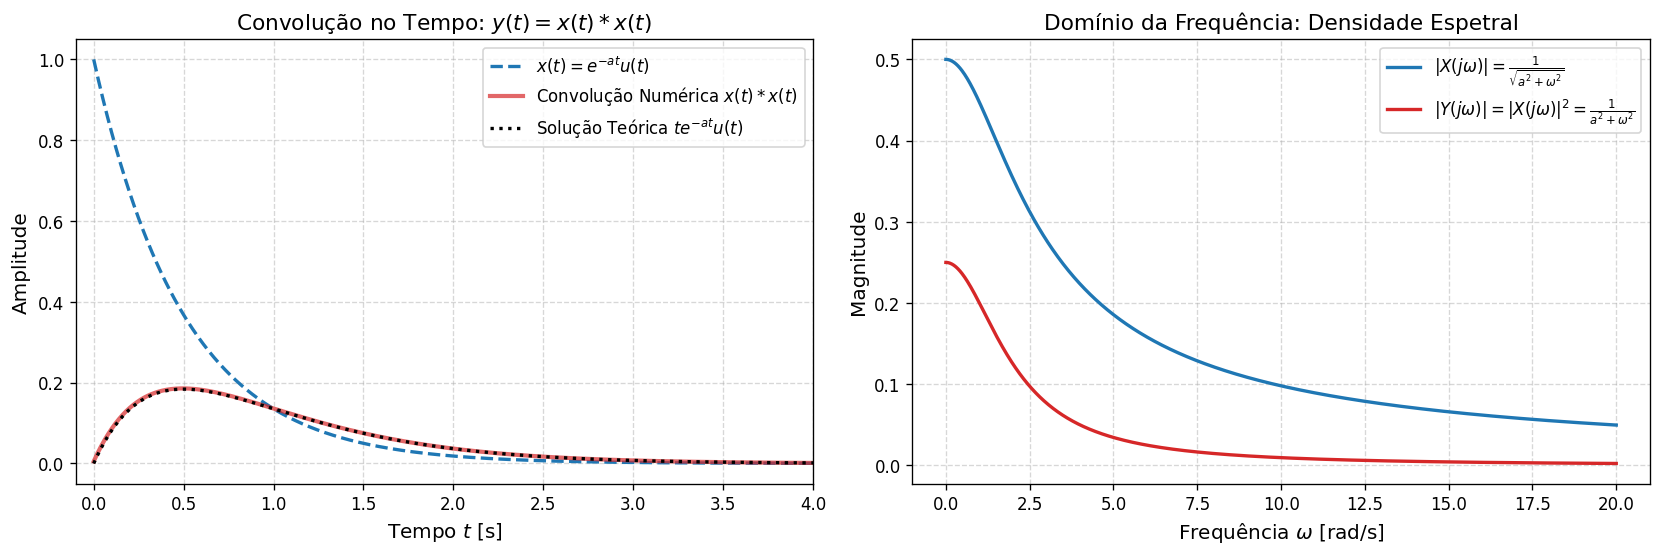

In [5]:
# ==============================================================================
# EXERCÍCIO 3: Validação Simbólica da Convolução e Simulação Numérica
# ==============================================================================

# 1. Convolução Simbólica com SymPy
t, tau, w = sp.symbols('t tau w', real=True)
a = sp.symbols('a', positive=True)

# Definição simbólica para t > 0
conv_integrand = sp.exp(-a*tau) * sp.exp(-a*(t - tau))
y_sym = sp.integrate(conv_integrand, (tau, 0, t))

print("=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 3 ===")
print("Integral de convolução entre 0 e t:", sp.simplify(y_sym))
print("Resultado esperado: t*exp(-a*t)")

# 2. Simulação Numérica e Validação da Propriedade da Convolução
a_param = 2.0
dt = 0.005
t_sim = np.arange(0, 5.0, dt)

# Sinais individuais x(t)
x_num = np.exp(-a_param * t_sim)

# Convolução numérica contínua: np.convolve com escalonamento por dt
y_num = np.convolve(x_num, x_num) * dt
t_conv = np.arange(0, len(y_num)) * dt

# Solução analítica teórica
y_teorico = t_conv * np.exp(-a_param * t_conv)

# Gráficos comparativos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

# Subplot 1: Domínio do tempo (Sinais elementares e Convolução)
ax1.plot(t_sim, x_num, label=r'$x(t) = e^{-at}u(t)$', color='#1f77b4', linestyle='--')
ax1.plot(t_conv[:len(t_sim)*2], y_num[:len(t_sim)*2], label=r'Convolução Numérica $x(t)*x(t)$', 
         color='#d62728', linewidth=2.5, alpha=0.7)
ax1.plot(t_conv[:len(t_sim)*2], y_teorico[:len(t_sim)*2], label=r'Solução Teórica $t e^{-at}u(t)$', 
         color='black', linestyle=':', linewidth=2)
ax1.set_xlim(-0.1, 4.0)
ax1.set_title(r'Convolução no Tempo: $y(t) = x(t) * x(t)$')
ax1.set_xlabel('Tempo $t$ [s]')
ax1.set_ylabel('Amplitude')
ax1.grid(True)
ax1.legend()

# Subplot 2: Domínio da frequência (|X(jw)| e |Y(jw)|)
w_eval = np.linspace(0, 20, 1000)
X_mag = 1.0 / np.sqrt(a_param**2 + w_eval**2)
Y_mag = 1.0 / (a_param**2 + w_eval**2)

ax2.plot(w_eval, X_mag, label=r'$|X(j\omega)| = \frac{1}{\sqrt{a^2 + \omega^2}}$', color='#1f77b4')
ax2.plot(w_eval, Y_mag, label=r'$|Y(j\omega)| = |X(j\omega)|^2 = \frac{1}{a^2 + \omega^2}$', color='#d62728')
ax2.set_title('Domínio da Frequência: Densidade Espetral')
ax2.set_xlabel(r'Frequência $\omega$ [rad/s]')
ax2.set_ylabel('Magnitude')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

## Exercício 15: Análise de Sistemas LIT em Série no Domínio da Frequência

Considere o sistema causal composto pela associação em série de dois subsistemas lineares e invariantes no tempo (LIT):
$$x(t) \longrightarrow \boxed{\quad S_1: \dot{z} + 6z = \dot{x} + 5x \quad} \stackrel{z(t)}{\longrightarrow} \boxed{\quad S_2: h_2(t) = e^{-10t}u(t) \quad} \longrightarrow y(t)$$

Onde:
* $S_1$ possui entrada $x(t)$, saída $z(t)$ e resposta impulsional $h_1(t)$.
* $S_2$ possui entrada $z(t)$, saída $y(t)$ e resposta impulsional $h_2(t)$.

---

### Alínea a) Resposta em Frequência de $S_1$ e $S_2$

#### 1. Subsistema $S_1$:
O subsistema $S_1$ é modelado pela Equação Diferencial Linear de Coeficientes Constantes:
$$\frac{dz(t)}{dt} + 6z(t) = \frac{dx(t)}{dt} + 5x(t)$$

Aplicando a Transformada de Fourier a ambos os membros da equação diferencial e recorrendo à propriedade da diferenciação no tempo, $\mathcal{F}\left\{\frac{df(t)}{dt}\right\} = j\omega F(j\omega)$:
$$(j\omega) Z(j\omega) + 6 Z(j\omega) = (j\omega) X(j\omega) + 5 X(j\omega)$$

Colocando os termos comuns em evidência:
$$(j\omega + 6) Z(j\omega) = (j\omega + 5) X(j\omega)$$

A resposta em frequência de $S_1$, $H_1(j\omega) = \frac{Z(j\omega)}{X(j\omega)}$, é dada por:
$$H_1(j\omega) = \frac{j\omega + 5}{j\omega + 6}$$

#### 2. Subsistema $S_2$:
A resposta impulsional é dada por $h_2(t) = e^{-10t}u(t)$.  
Aplicando o par fundamental deduzido no Exercício 3 (com $a = 10 > 0$):
$$H_2(j\omega) = \mathcal{F}\{h_2(t)\} = \int_{0}^{+\infty} e^{-10t} e^{-j\omega t} dt = \frac{1}{j\omega + 10}$$

---

### Alínea b) Resposta em Frequência do Sistema Global $H(j\omega)$

Como os subsistemas $S_1$ e $S_2$ estão ligados em série (cascata):
$$Z(j\omega) = H_1(j\omega) X(j\omega)$$
$$Y(j\omega) = H_2(j\omega) Z(j\omega) = H_2(j\omega) [H_1(j\omega) X(j\omega)] = [H_1(j\omega) \cdot H_2(j\omega)] X(j\omega)$$

A resposta em frequência do sistema global é dada pelo produto das respostas em frequência individuais:
$$H(j\omega) = H_1(j\omega) \cdot H_2(j\omega) = \left( \frac{j\omega + 5}{j\omega + 6} \right) \left( \frac{1}{j\omega + 10} \right) = \frac{j\omega + 5}{(j\omega + 6)(j\omega + 10)}$$

Multiplicando os fatores do polinómio característico no denominador:
$$(j\omega + 6)(j\omega + 10) = (j\omega)^2 + 10(j\omega) + 6(j\omega) + 60 = (j\omega)^2 + 16(j\omega) + 60$$

Assim:
$$H(j\omega) = \frac{j\omega + 5}{(j\omega)^2 + 16(j\omega) + 60} = \frac{j\omega + 5}{-\omega^2 + 16j\omega + 60}$$

---

### Alínea c) Resposta Impulsional do Sistema Global $h(t)$

A resposta impulsional obtém-se através da Transformada Inversa de Fourier de $H(j\omega)$:
$$h(t) = \mathcal{F}^{-1}\{H(j\omega)\}$$

1. **Decomposição em Frações Simples:**  
   Como o polinómio do numerador possui grau inferior ao denominador (grau 1 versus grau 2), decompomos em frações simples com polos reais simples em $s = -6$ e $s = -10$ (adotando $s = j\omega$):
   $$H(j\omega) = \frac{j\omega + 5}{(j\omega + 6)(j\omega + 10)} = \frac{A}{j\omega + 6} + \frac{B}{j\omega + 10}$$

   Determinando os coeficientes $A$ e $B$ pelo método dos resíduos de Heaviside:
   $$A = \left[ (j\omega + 6) H(j\omega) \right]_{j\omega = -6} = \left. \frac{j\omega + 5}{j\omega + 10} \right|_{j\omega = -6} = \frac{-6 + 5}{-6 + 10} = \frac{-1}{4} = -0.25$$
   $$B = \left[ (j\omega + 10) H(j\omega) \right]_{j\omega = -10} = \left. \frac{j\omega + 5}{j\omega + 6} \right|_{j\omega = -10} = \frac{-10 + 5}{-10 + 6} = \frac{-5}{-4} = \frac{5}{4} = 1.25$$

   Logo:
   $$H(j\omega) = -\frac{1}{4} \cdot \frac{1}{j\omega + 6} + \frac{5}{4} \cdot \frac{1}{j\omega + 10}$$

2. **Inversão Termo a Termo:**  
   Sendo o sistema causal e com polos com parte real estritamente negativa ($\text{Re}\{p_1\} = -6 < 0$, $\text{Re}\{p_2\} = -10 < 0$), o sistema é BIBO estável e a sua resposta impulsional é causal ($h(t) = 0$ para $t < 0$):
   $$\mathcal{F}^{-1}\left\{ \frac{1}{j\omega + 6} \right\} = e^{-6t} u(t)$$
   $$\mathcal{F}^{-1}\left\{ \frac{1}{j\omega + 10} \right\} = e^{-10t} u(t)$$

   Pela linearidade da transformada inversa:
   $$h(t) = \left( -\frac{1}{4} e^{-6t} + \frac{5}{4} e^{-10t} \right) u(t)$$

* **Verificação do Valor Inicial $h(0^+)$:**
  $$h(0^+) = -\frac{1}{4} e^0 + \frac{5}{4} e^0 = -\frac{1}{4} + \frac{5}{4} = 1$$
  Este resultado é consistente com o Teorema do Valor Inicial: $\lim_{s \to \infty} s H(s) = \lim_{s \to \infty} \frac{s(s+5)}{(s+6)(s+10)} = 1$.

---

### Alínea d) Equação Diferencial Linear de Coeficientes Constantes entre $y(t)$ e $x(t)$

A partir da resposta em frequência global do sistema:
$$H(j\omega) = \frac{Y(j\omega)}{X(j\omega)} = \frac{j\omega + 5}{(j\omega)^2 + 16(j\omega) + 60}$$

Multiplicando os termos em cruz:
$$\left[ (j\omega)^2 + 16(j\omega) + 60 \right] Y(j\omega) = (j\omega + 5) X(j\omega)$$
$$(j\omega)^2 Y(j\omega) + 16 (j\omega) Y(j\omega) + 60 Y(j\omega) = (j\omega) X(j\omega) + 5 X(j\omega)$$

Aplicando a Transformada Inversa de Fourier a cada parcela, tendo presente a propriedade $(j\omega)^k F(j\omega) \stackrel{\mathcal{F}^{-1}}{\longleftrightarrow} \frac{d^k f(t)}{dt^k}$:
$$\frac{d^2 y(t)}{dt^2} + 16 \frac{dy(t)}{dt} + 60 y(t) = \frac{dx(t)}{dt} + 5 x(t)$$

ou, na notação diferencial compacta com pontos:
$$\ddot{y}(t) + 16\dot{y}(t) + 60y(t) = \dot{x}(t) + 5x(t)$$

=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 15 ===
H1(s): (s + 5)/(s + 6)
H2(s): 1/(s + 10)
H(s) Global:             (s + 5)/((s + 6)*(s + 10))
Frações Simples de H(s): 5/(4*(s + 10)) - 1/(4*(s + 6))


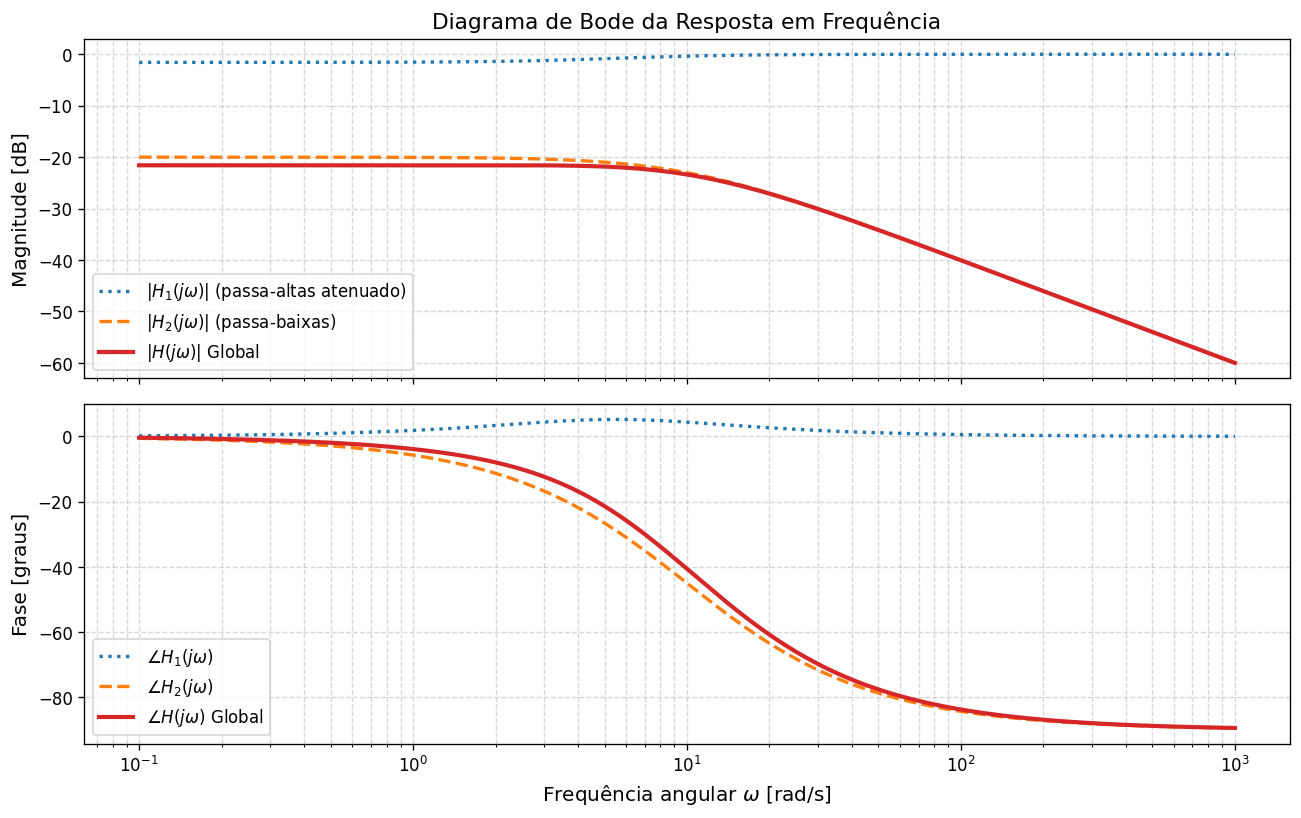

In [6]:
# ==============================================================================
# EXERCÍCIO 15: Validação Algébrica Simbólica e Diagramas de Bode
# ==============================================================================

# 1. Resolução Simbólica com SymPy
s, w, t = sp.symbols('s w t', real=True)

# Subsistemas e Sistema Global no plano s (onde s = j*w)
H1_s = (s + 5) / (s + 6)
H2_s = 1 / (s + 10)
H_s = sp.simplify(H1_s * H2_s)

# Decomposição em frações simples
H_frac = sp.apart(H_s, s)

print("=== VERIFICAÇÃO SIMBÓLICA (SymPy) - Exercício 15 ===")
print("H1(s):", H1_s)
print("H2(s):", H2_s)
print("H(s) Global:            ", H_s)
print("Frações Simples de H(s):", H_frac)

# 2. Resposta em Frequência (Diagrama de Bode) com SciPy e Matplotlib
num_H = [1, 5]
den_H = [1, 16, 60]
sys_H = signal.lti(num_H, den_H)

w_bode = np.logspace(-1, 3, 1000)
w_eval, H_resp = signal.freqs(num_H, den_H, worN=w_bode)
_, H1_resp = signal.freqs([1, 5], [1, 6], worN=w_bode)
_, H2_resp = signal.freqs([1], [1, 10], worN=w_bode)

fig, (ax_mag, ax_pha) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Diagrama de Magnitude (dB)
ax_mag.semilogx(w_eval, 20 * np.log10(np.abs(H1_resp)), label=r'$|H_1(j\omega)|$ (passa-altas atenuado)', linestyle=':')
ax_mag.semilogx(w_eval, 20 * np.log10(np.abs(H2_resp)), label=r'$|H_2(j\omega)|$ (passa-baixas)', linestyle='--')
ax_mag.semilogx(w_eval, 20 * np.log10(np.abs(H_resp)), label=r'$|H(j\omega)|$ Global', color='#d62728', linewidth=2.5)
ax_mag.set_title('Diagrama de Bode da Resposta em Frequência')
ax_mag.set_ylabel('Magnitude [dB]')
ax_mag.grid(True, which='both')
ax_mag.legend()

# Diagrama de Fase (graus)
ax_pha.semilogx(w_eval, np.rad2deg(np.unwrap(np.angle(H1_resp))), label=r'$\angle H_1(j\omega)$', linestyle=':')
ax_pha.semilogx(w_eval, np.rad2deg(np.unwrap(np.angle(H2_resp))), label=r'$\angle H_2(j\omega)$', linestyle='--')
ax_pha.semilogx(w_eval, np.rad2deg(np.unwrap(np.angle(H_resp))), label=r'$\angle H(j\omega)$ Global', color='#d62728', linewidth=2.5)
ax_pha.set_xlabel(r'Frequência angular $\omega$ [rad/s]')
ax_pha.set_ylabel('Fase [graus]')
ax_pha.grid(True, which='both')
ax_pha.legend()

plt.tight_layout()
plt.show()

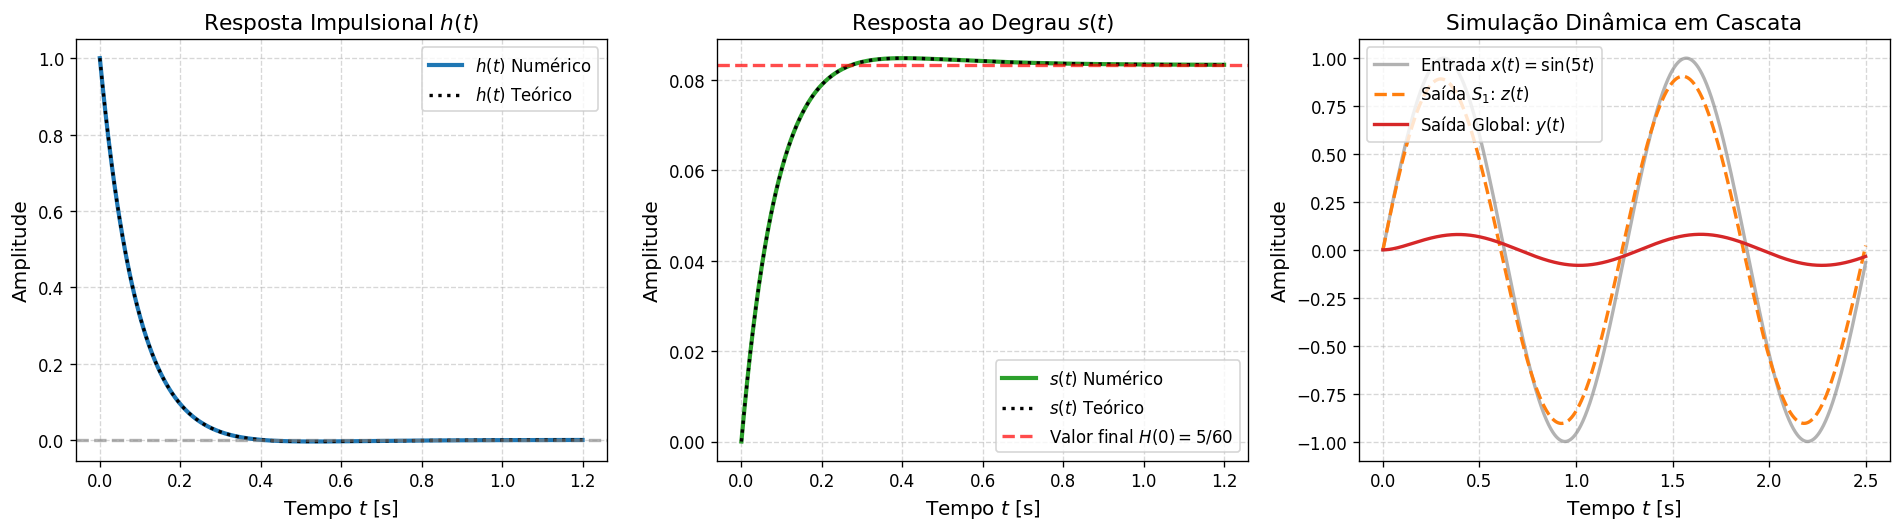

In [7]:
# ==============================================================================
# EXERCÍCIO 15: Análise Temporal: Resposta Impulsional, ao Degrau e Simulação Dinâmica
# ==============================================================================

# Definição dos sistemas LTI em scipy.signal
sys_S1 = signal.lti([1, 5], [1, 6])
sys_S2 = signal.lti([1], [1, 10])
sys_global = signal.lti([1, 5], [1, 16, 60])

t_vec = np.linspace(0, 1.2, 1000)

# 1. Resposta Impulsional h(t)
t_imp, h_num = signal.impulse(sys_global, T=t_vec)
h_teorico = (-0.25 * np.exp(-6 * t_vec) + 1.25 * np.exp(-10 * t_vec))

# 2. Resposta ao Degrau de Heaviside s(t)
t_step, s_num = signal.step(sys_global, T=t_vec)
# s(t) teorico = integral de h(tau) = 5/60 + (1/24)*exp(-6t) - (1/8)*exp(-10t)
s_teorico = 5/60 + (1/24)*np.exp(-6*t_vec) - (1/8)*np.exp(-10*t_vec)

# 3. Simulação Dinâmica de Entrada e Saída
t_sim = np.linspace(0, 2.5, 2000)
# Entrada: Onda sinusoidal modulada por degrau de Heaviside
w0 = 5.0 # rad/s
x_input = np.sin(w0 * t_sim)

# Resposta intermédia z(t) e resposta final y(t)
_, z_out, _ = signal.lsim(sys_S1, U=x_input, T=t_sim)
_, y_out, _ = signal.lsim(sys_global, U=x_input, T=t_sim)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))

# Resposta Impulsional
axs[0].plot(t_imp, h_num, label=r'$h(t)$ Numérico', color='#1f77b4', linewidth=2.5)
axs[0].plot(t_vec, h_teorico, label=r'$h(t)$ Teórico', color='black', linestyle=':', linewidth=2)
axs[0].axhline(0, color='gray', linestyle='--', alpha=0.6)
axs[0].set_title(r'Resposta Impulsional $h(t)$')
axs[0].set_xlabel('Tempo $t$ [s]')
axs[0].set_ylabel('Amplitude')
axs[0].grid(True)
axs[0].legend()

# Resposta ao Degrau
axs[1].plot(t_step, s_num, label=r'$s(t)$ Numérico', color='#2ca02c', linewidth=2.5)
axs[1].plot(t_vec, s_teorico, label=r'$s(t)$ Teórico', color='black', linestyle=':', linewidth=2)
axs[1].axhline(5/60, color='red', linestyle='--', alpha=0.7, label=r'Valor final $H(0) = 5/60$')
axs[1].set_title(r'Resposta ao Degrau $s(t)$')
axs[1].set_xlabel('Tempo $t$ [s]')
axs[1].set_ylabel('Amplitude')
axs[1].grid(True)
axs[1].legend()

# Simulação Dinâmica
axs[2].plot(t_sim, x_input, label=r'Entrada $x(t) = \sin(5t)$', color='gray', alpha=0.6)
axs[2].plot(t_sim, z_out, label=r'Saída $S_1$: $z(t)$', color='#ff7f0e', linestyle='--')
axs[2].plot(t_sim, y_out, label=r'Saída Global: $y(t)$', color='#d62728', linewidth=2)
axs[2].set_title('Simulação Dinâmica em Cascata')
axs[2].set_xlabel('Tempo $t$ [s]')
axs[2].set_ylabel('Amplitude')
axs[2].grid(True)
axs[2].legend()

plt.tight_layout()
plt.show()

## 2. Síntese Conceptual, Relação com Laplace e Conclusões

A resolução desta folha prática permitiu consolidar competências nucleares na análise de sinais e sistemas no domínio da frequência:

1. **Eficiência no Uso das Propriedades Operacionais:**
   * A propriedade da **Dualidade** evidenciou ser um instrumento matemático poderoso, permitindo obter a transformada de funções racionais da família de Cauchy ($\frac{1}{a^2 + t^2}$) a partir do par exponencial simétrico sem necessidade de recorrer à integração por resíduos no plano complexo.
   * A propriedade da **Convolução no Tempo** confirmou que operações temporais complexas se convertem em produtos algébricos imediatos no domínio da frequência, simplificando significativamente a determinação de transformadas inversas de produtos como $\frac{1}{(a+j\omega)^2}$.

2. **Interconexão de Sistemas Lineares e Invariantes no Tempo (LIT):**
   * Constatou-se que a associação em série de subsistemas equivale à multiplicação das suas respetivas respostas em frequência $H(j\omega) = H_1(j\omega) H_2(j\omega)$.
   * Estabeleceu-se uma ponte direta e unívoca entre a formulação no domínio do tempo (equações diferenciais lineares de coeficientes constantes e resposta impulsional $h(t)$) e a representação no domínio da frequência (funções racionais de $j\omega$).

3. **Unificação Conceptual: Fourier e Laplace com $s = j\omega$:**
   * Compreendeu-se que a Transformada de Fourier corresponde à Transformada de Laplace avaliada diretamente no eixo imaginário, $H(j\omega) = \left. H(s) \right|_{s = j\omega}$, desde que o eixo $j\omega$ pertença à Região de Convergência (ROC) do sistema.
   * Em sistemas causais estáveis, a exigência de todos os polos se localizarem estritamente no semiplano esquerdo ($\text{Re}\{p_k\} < 0$) assegura a integrabilidade absoluta de $h(t)$ e a convergência de $H(j\omega)$, garantindo a estabilidade em regime permanente perante excitações sinusoidais.

4. **Validação Cruzada Computacional:**
   * A utilização conjunta de ferramentas simbólicas (`SymPy`) e numéricas (`NumPy`, `SciPy`, `Matplotlib`) permitiu comprovar os desenvolvimentos analíticos com consistência e adquirir sensibilidade intuitiva sobre o compromisso tempo-frequência inerente a qualquer fenómeno em Engenharia Electrotécnica.